# Bank Marketing EDA

This notebook reviews the bank marketing dataset, summarizes the available features, and looks for patterns that relate to subscription outcomes.


In [41]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    recall_score,
)

bank = pd.read_csv("../bank-additional-full.csv", sep=";")
bank = bank.drop(columns=["duration"], errors="ignore")
print(bank.head())
print(f"Dataset shape: {bank.shape}")


   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  campaign  pdays  previous     poutcome  emp.var.rate  \
0   may         mon         1    999         0  nonexistent           1.1   
1   may         mon         1    999         0  nonexistent           1.1   
2   may         mon         1    999         0  nonexistent           1.1   
3   may         mon         1    999         0  nonexistent           1.1   
4   may         mon         1    999         0  nonexistent           1.1   

   cons.price.idx  cons.conf.idx  euribor3m  nr.employed   y  
0          93.994

In [42]:
bank.info()
print("\nNumerical summary:\n")
print(bank.describe(include=[np.number]).T)
print("\nCategorical summary:\n")
print(bank.describe(include=["object", "category"]).T)
print("\nColumns:\n", bank.columns.tolist())


<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  campaign        41188 non-null  int64  
 11  pdays           41188 non-null  int64  
 12  previous        41188 non-null  int64  
 13  poutcome        41188 non-null  str    
 14  emp.var.rate    41188 non-null  float64
 15  cons.price.idx  41188 non-null  float64
 16  cons.conf.idx   41188 non-null  float64
 17  euribor3m       41188 non-null  float64
 1

C:\Users\chuck\AppData\Local\Temp\ipykernel_29344\4188337137.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(bank.describe(include=["object", "category"]).T)


## Univariate distributions

The sections below summarize continuous and categorical distributions before evaluating how those variables relate to campaign success.


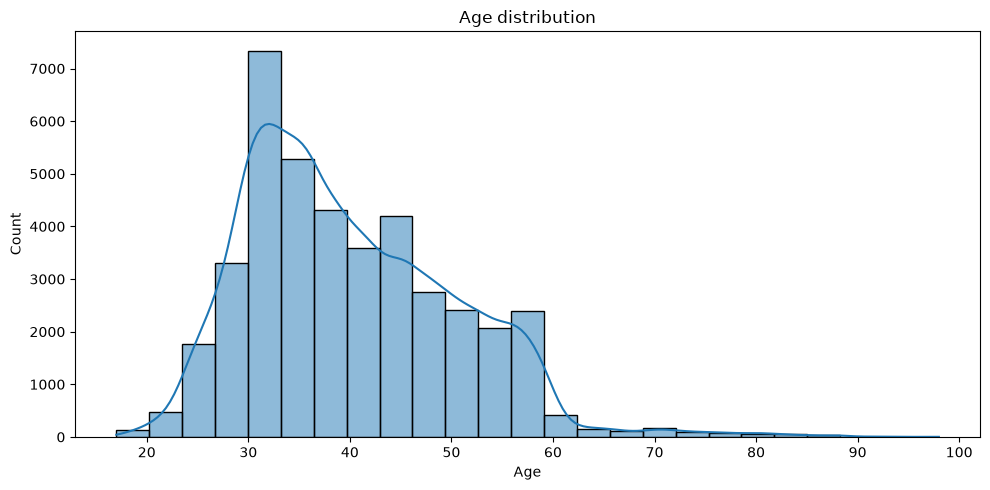

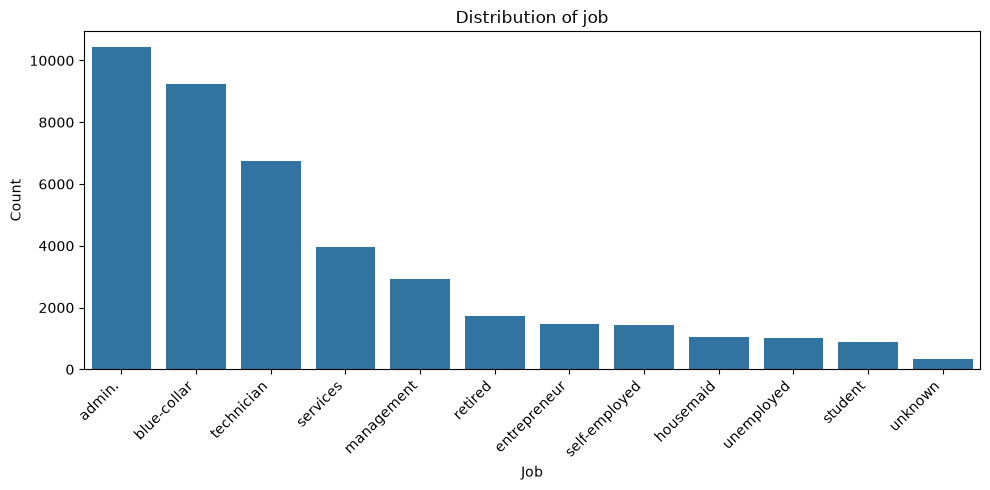


job counts:
job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64


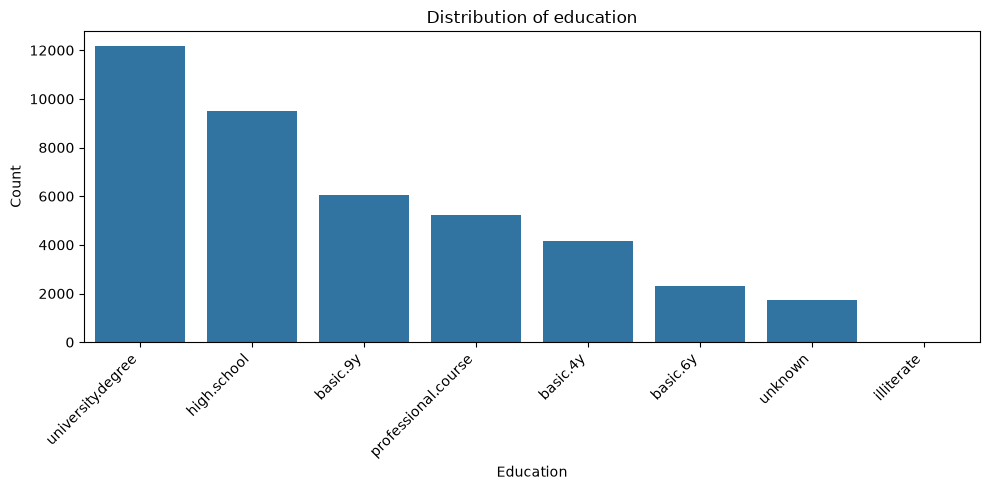


education counts:
education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64


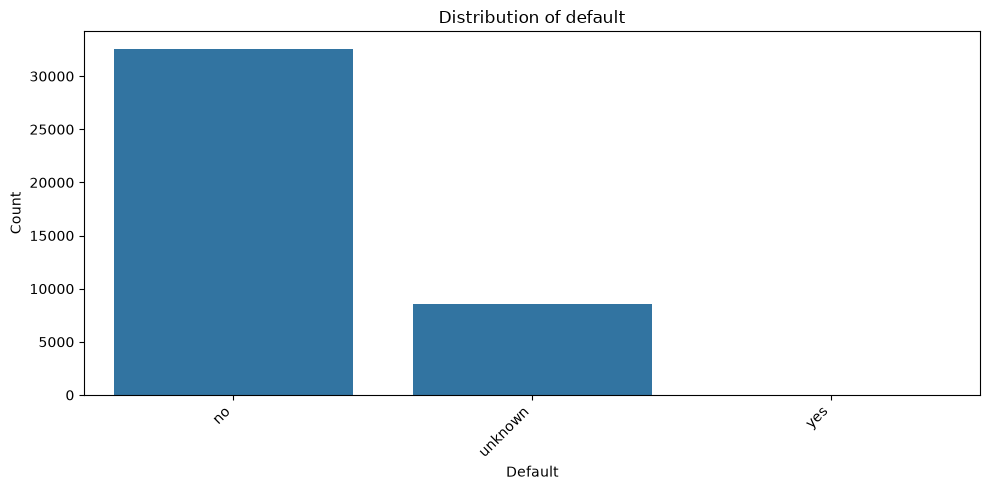


default counts:
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64


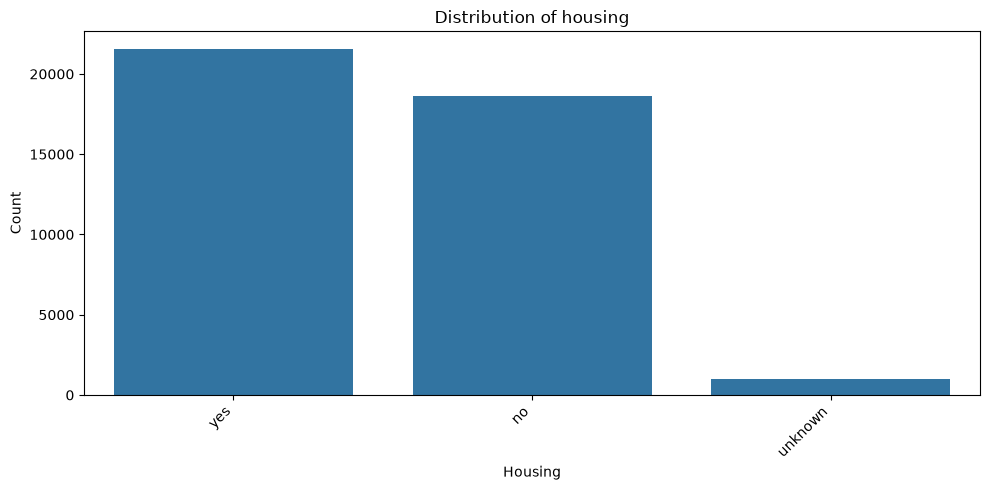


housing counts:
housing
yes        21576
no         18622
unknown      990
Name: count, dtype: int64


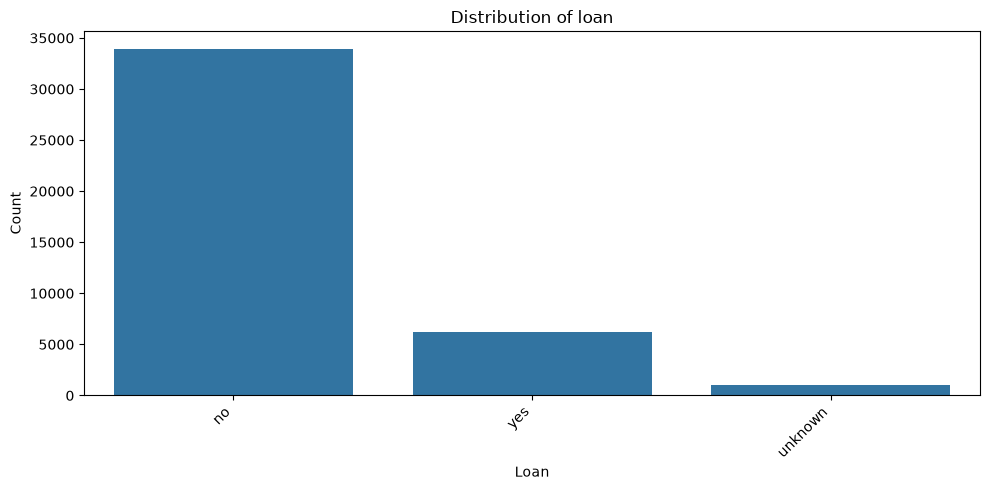


loan counts:
loan
no         33950
yes         6248
unknown      990
Name: count, dtype: int64


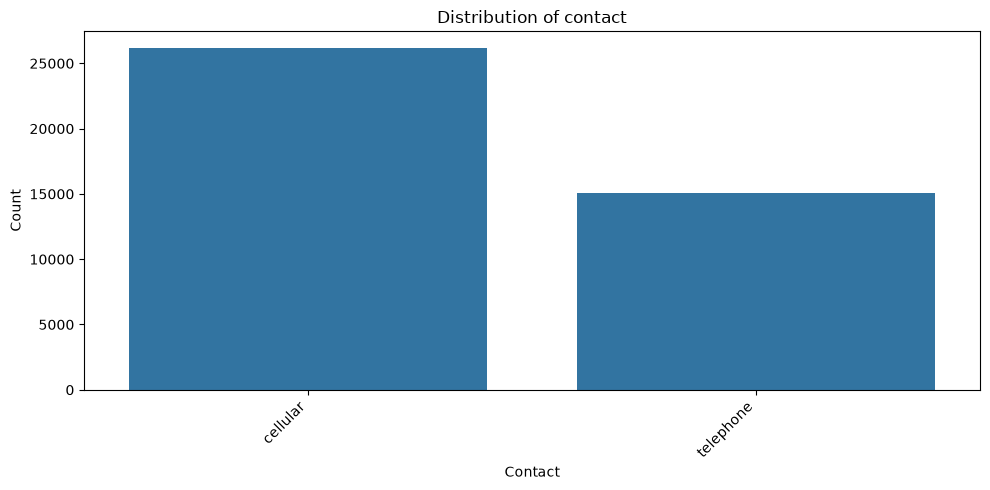


contact counts:
contact
cellular     26144
telephone    15044
Name: count, dtype: int64


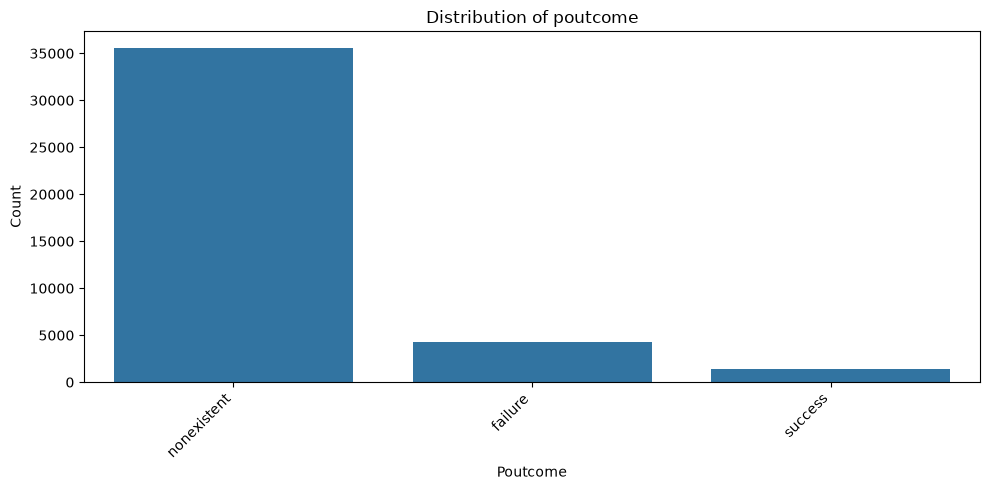


poutcome counts:
poutcome
nonexistent    35563
failure         4252
success         1373
Name: count, dtype: int64


In [43]:
plt.figure(figsize=(10, 5))
sns.histplot(bank["age"], kde=True, bins=25)
plt.title("Age distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

for col in ["job", "education", "default", "housing", "loan", "contact", "poutcome"]:
    counts = bank[col].value_counts()
    plt.figure(figsize=(10, 5))
    sns.barplot(x=counts.index.astype(str), y=counts.values)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
    print(f"\n{col} counts:\n{counts}")


## Conversion and campaign outcomes

This block focuses on response rates and how variables like age, campaign recency, and category segments are associated with subscription success.


Overall subscription rate: 11.27%

Subscription rate by job:
          job  total  subscribers  subscription_rate
      student    875          275           0.314286
      retired   1720          434           0.252326
   unemployed   1014          144           0.142012
       admin.  10422         1352           0.129726
   management   2924          328           0.112175
      unknown    330           37           0.112121
   technician   6743          730           0.108260
self-employed   1421          149           0.104856
    housemaid   1060          106           0.100000
 entrepreneur   1456          124           0.085165
     services   3969          323           0.081381
  blue-collar   9254          638           0.068943


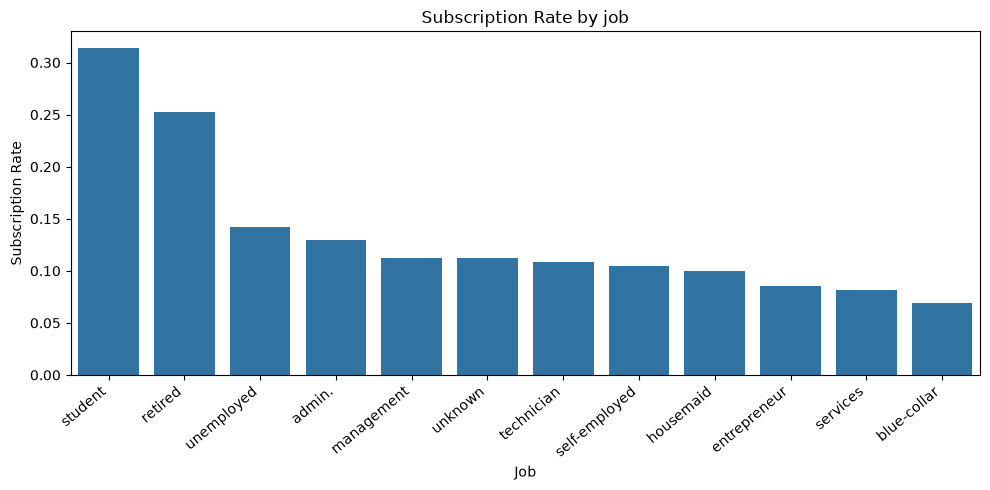


Subscription rate by education:
          education  total  subscribers  subscription_rate
         illiterate     18            4           0.222222
            unknown   1731          251           0.145003
  university.degree  12168         1670           0.137245
professional.course   5243          595           0.113485
        high.school   9515         1031           0.108355
           basic.4y   4176          428           0.102490
           basic.6y   2292          188           0.082024
           basic.9y   6045          473           0.078246


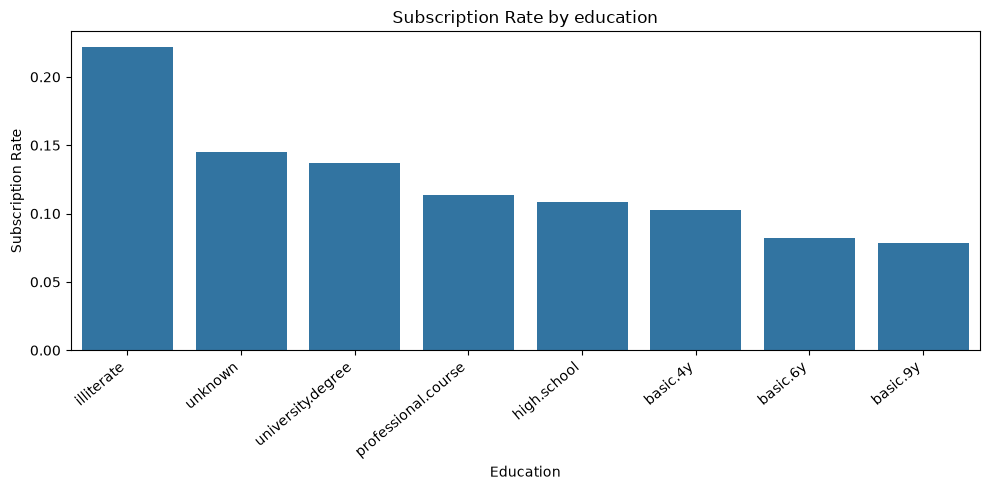


Subscription rate by marital:
 marital  total  subscribers  subscription_rate
 unknown     80           12           0.150000
  single  11568         1620           0.140041
divorced   4612          476           0.103209
 married  24928         2532           0.101573


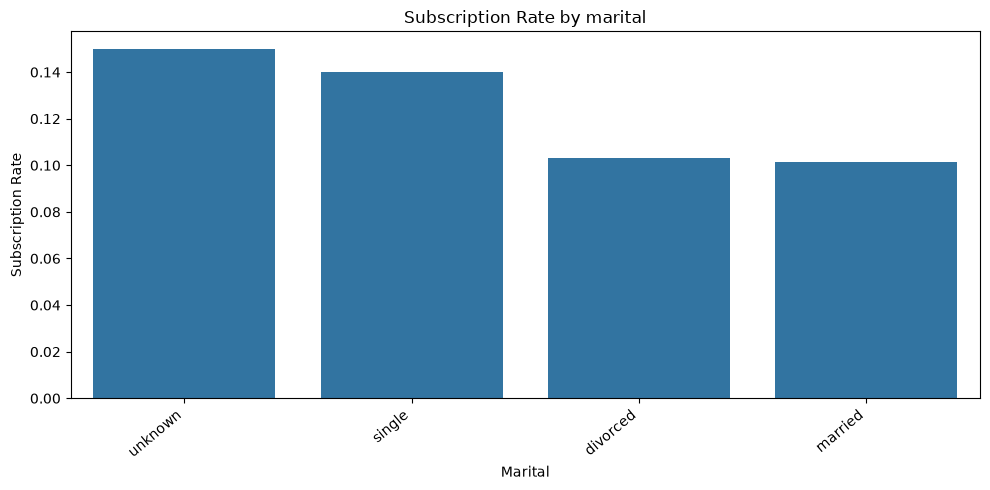


Subscription rate by housing:
housing  total  subscribers  subscription_rate
    yes  21576         2507           0.116194
     no  18622         2026           0.108796
unknown    990          107           0.108081


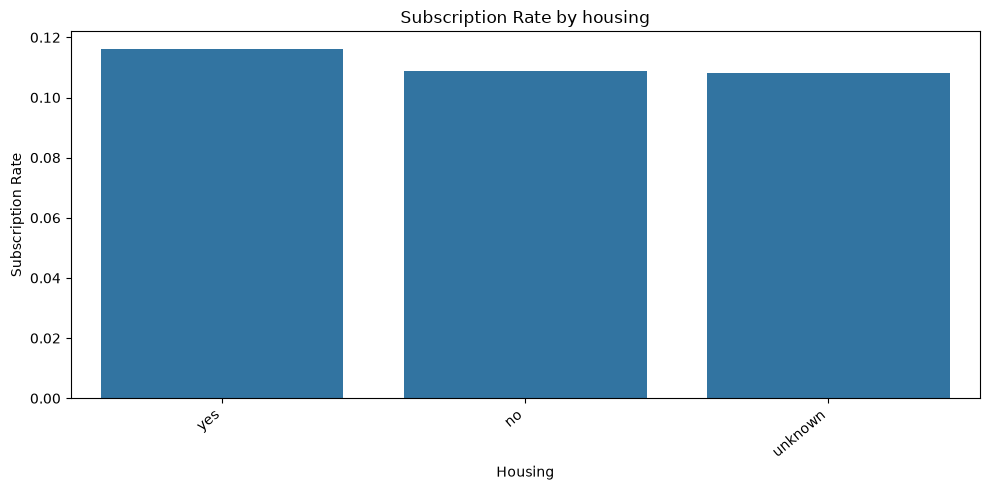


Subscription rate by loan:
   loan  total  subscribers  subscription_rate
     no  33950         3850           0.113402
    yes   6248          683           0.109315
unknown    990          107           0.108081


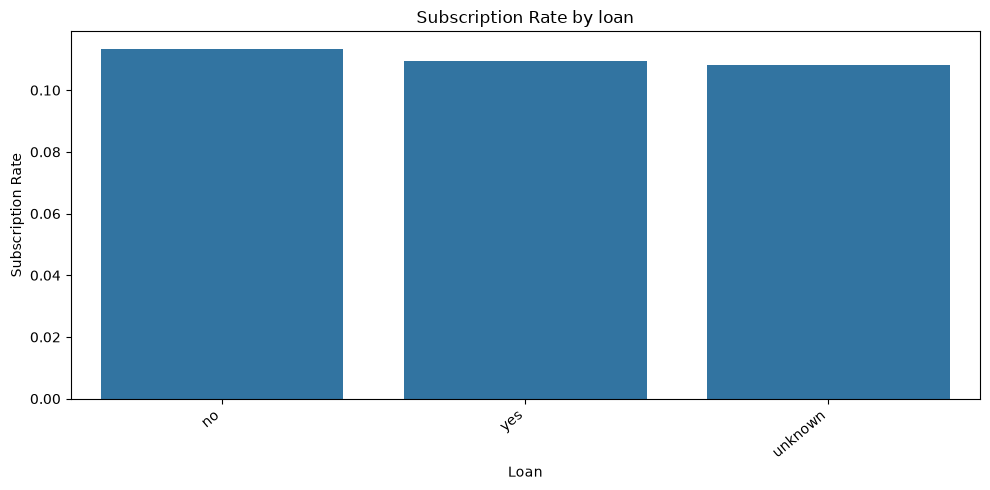


Subscription rate by default:
default  total  subscribers  subscription_rate
     no  32588         4197            0.12879
unknown   8597          443            0.05153
    yes      3            0            0.00000


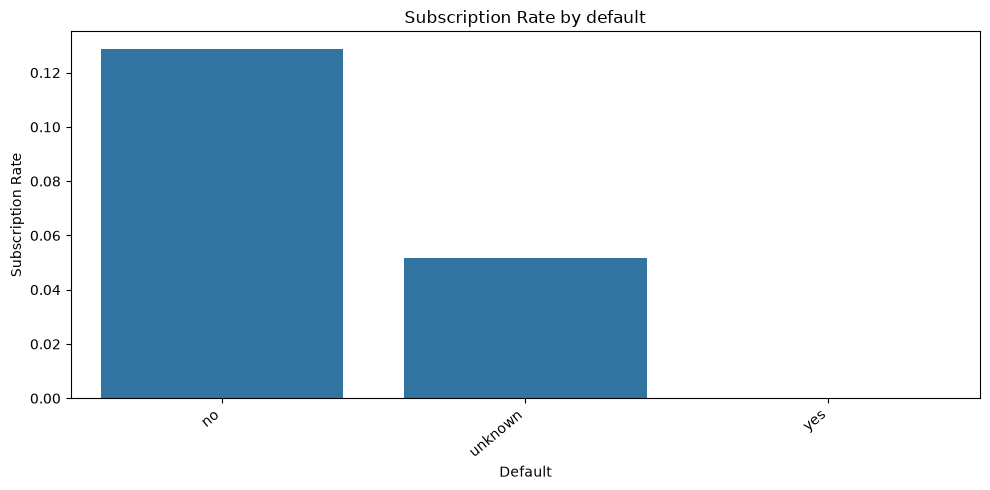

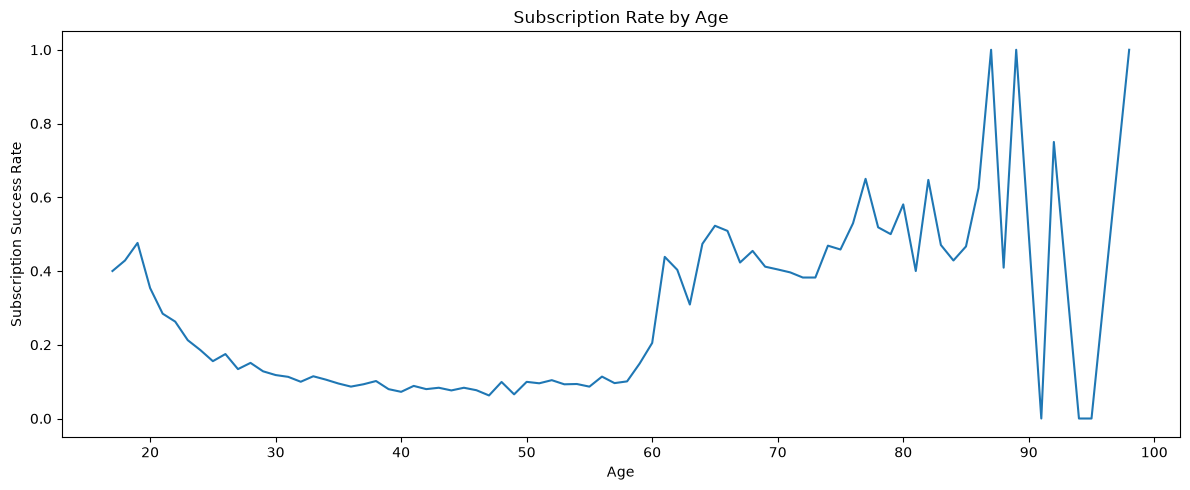

In [44]:
success_rate = (bank["y"] == "yes").mean()
print(f"Overall subscription rate: {success_rate:.2%}")

for col in ["job", "education", "marital", "housing", "loan", "default"]:
    summary = (
        bank.groupby(col, observed=True)["y"]
        .agg(total="count", subscribers=lambda s: (s == "yes").sum())
        .reset_index()
    )
    summary["subscription_rate"] = summary["subscribers"] / summary["total"]
    summary = summary.sort_values("subscription_rate", ascending=False)
    print(f"\nSubscription rate by {col}:")
    print(summary.to_string(index=False))

    plt.figure(figsize=(10, 5))
    sns.barplot(data=summary, x=col, y="subscription_rate")
    plt.title(f"Subscription Rate by {col}")
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("Subscription Rate")
    plt.xticks(rotation=40, ha="right")
    plt.tight_layout()
    plt.show()

age_success = bank.groupby("age")["y"].apply(lambda s: (s == "yes").mean())
plt.figure(figsize=(12, 5))
sns.lineplot(x=age_success.index, y=age_success.values)
plt.xlabel("Age")
plt.ylabel("Subscription Success Rate")
plt.title("Subscription Rate by Age")
plt.tight_layout()
plt.show()



Success rate by previous contact timing:
                          success_rate  count
pdays_bucket                                 
0 days                        0.666667     15
1-5 days                      0.630435    690
6-10 days                     0.669967    606
11-20 days                    0.556122    196
21-50 days                    0.875000      8
51-100 days                        NaN      0
101-500 days                       NaN      0
501-998 days                       NaN      0
Not previously contacted      0.092582  39673


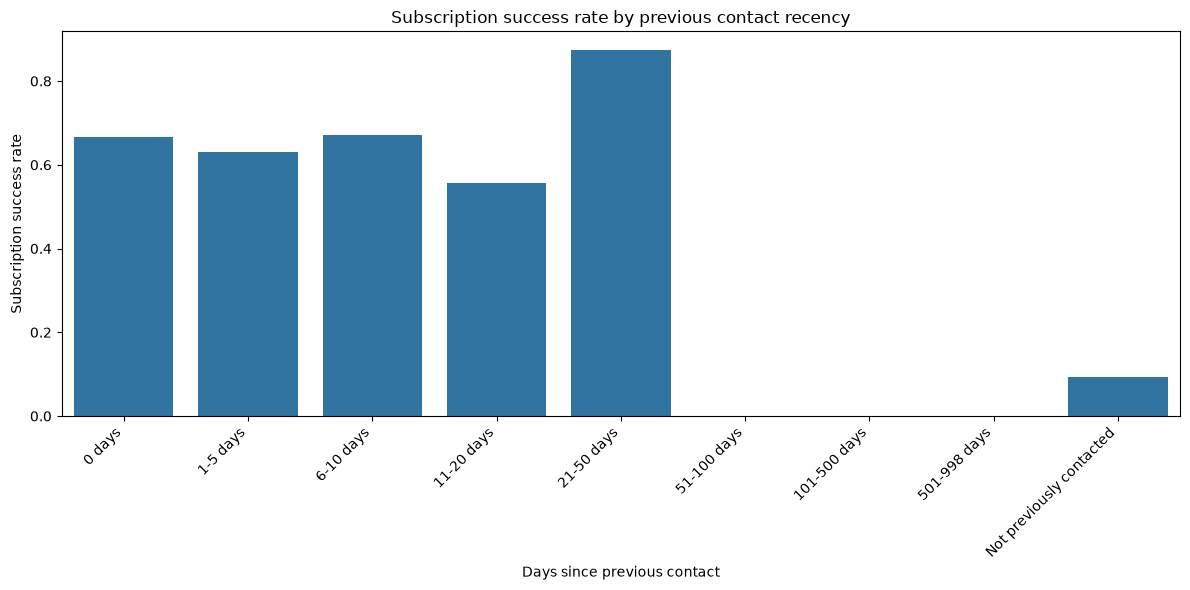

In [45]:
# Previous contact analysis
bank["success"] = (bank["y"] == "yes").astype(int)

pdays = bank["pdays"].copy()
bins = [-1, 0, 5, 10, 20, 50, 100, 500, 998, 999]
labels = [
    "0 days",
    "1-5 days",
    "6-10 days",
    "11-20 days",
    "21-50 days",
    "51-100 days",
    "101-500 days",
    "501-998 days",
    "Not previously contacted",
]

pdays_summary = (
    bank.assign(pdays_bucket=pd.cut(pdays, bins=bins, labels=labels, include_lowest=True))
    .groupby("pdays_bucket", observed=False)
    .agg(success_rate=("success", "mean"), count=("success", "size"))
)
print("\nSuccess rate by previous contact timing:")
print(pdays_summary)

plt.figure(figsize=(12, 6))
sns.barplot(x=pdays_summary.index.astype(str), y=pdays_summary["success_rate"])
plt.xlabel("Days since previous contact")
plt.ylabel("Subscription success rate")
plt.title("Subscription success rate by previous contact recency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## Model baseline

A simple decision tree provides a quick classification baseline and a useful view of where the model struggles.


Test accuracy: 0.8466

Recall by subscription outcome:
 no     0.912038
yes    0.330819
Name: Recall, dtype: float64

Classification report:

              precision    recall  f1-score   support

          no       0.91      0.91      0.91      7310
         yes       0.32      0.33      0.33       928

    accuracy                           0.85      8238
   macro avg       0.62      0.62      0.62      8238
weighted avg       0.85      0.85      0.85      8238



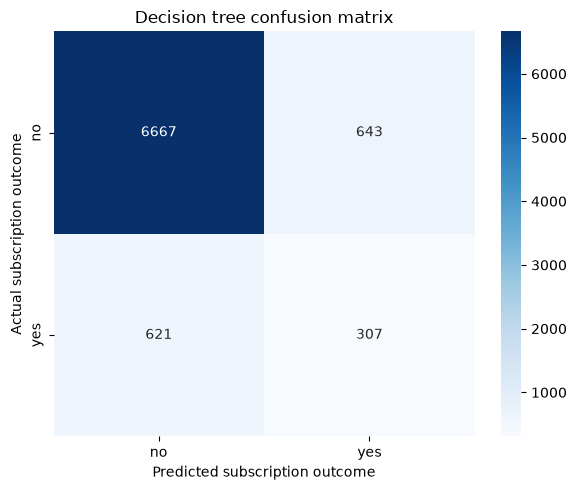

In [46]:
X = bank.drop(columns=["y", "success", "poutcome"], errors="ignore").copy()
y = bank["y"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

categorical_cols = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
numerical_cols = X.select_dtypes(include=[np.number]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("numerical", "passthrough", numerical_cols),
    ]
)

clf = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("tree", DecisionTreeClassifier(random_state=8675309, class_weight="balanced")),
    ]
)

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")

recall_by_class = pd.Series(
    recall_score(y_test, y_pred, labels=["no", "yes"], average=None, zero_division=0),
    index=["no", "yes"],
    name="Recall",
)
print("\nRecall by subscription outcome:\n", recall_by_class)
print("\nClassification report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=["no", "yes"])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["no", "yes"],
    yticklabels=["no", "yes"],
)
plt.xlabel("Predicted subscription outcome")
plt.ylabel("Actual subscription outcome")
plt.title("Decision tree confusion matrix")
plt.tight_layout()
plt.show()
